# PlantGuard AI dataset EDA

This notebook reads the verified Mendeley archive inventory and calls reusable project modules. Folder names are treated as the source labels. Run `python scripts/prepare_data.py` first, then run the EDA cells.


In [1]:
from pathlib import Path
import pandas as pd
import sys
ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.plantguard.eda import run_eda
ARCHIVE = ROOT / "data/raw/Custom Dataset for Plant Species and Disease Detec/Ranveer_Realistic_dataset_2000_1126.zip"


In [2]:
summary = run_eda(ARCHIVE, ROOT / "dataset/image_inventory.csv", ROOT / "dataset/class_distribution.csv", ROOT / "results/figures", ROOT / "dataset/image_size_stats.csv")
summary


{'images': 9469,
 'classes': 41,
 'imbalance_ratio': 57.608695652173914,
 'aspect_ratio_min': 0.5621669626998224,
 'aspect_ratio_max': 1.7777777777777777,
 'aspect_ratio_mean': 1.4059384580343954,
 'aspect_ratio_median': 1.7761989342806397,
 'unique_dimensions': 5}

In [3]:
counts = pd.read_csv(ROOT / "dataset/class_distribution.csv")
counts["percentage"] = 100 * counts.image_count / counts.image_count.sum()
counts.sort_values("image_count")


,class_name,image_count,percentage
4,grape_mineral_dificiency,23,0.242898
31,guava_scab_manganese_dificiency,24,0.253459
25,guava_cholrophyl_sucking_insect,25,0.264019
24,guava_chlorosis_scab,26,0.274580
16,groundnut_cercospora_personata_millibug,30,0.316823
39,soyabean_leaf_eating_caterpillar_mineral_dific...,34,0.359066
11,groundnut_cercospora_arachidicola_insect_eating,44,0.464674
22,guava_cephaleuros_parasiticus,46,0.485796
32,soyabean_cercospora_sojina,53,0.559721
8,grape_powdery_mildew_insect_eating,54,0.570282


## Figures

The reusable EDA module saves count and percentage bar plots, one sample image per class, and image size/aspect ratio analysis under `results/figures/`. The imbalance ratio is the largest class count divided by the smallest.


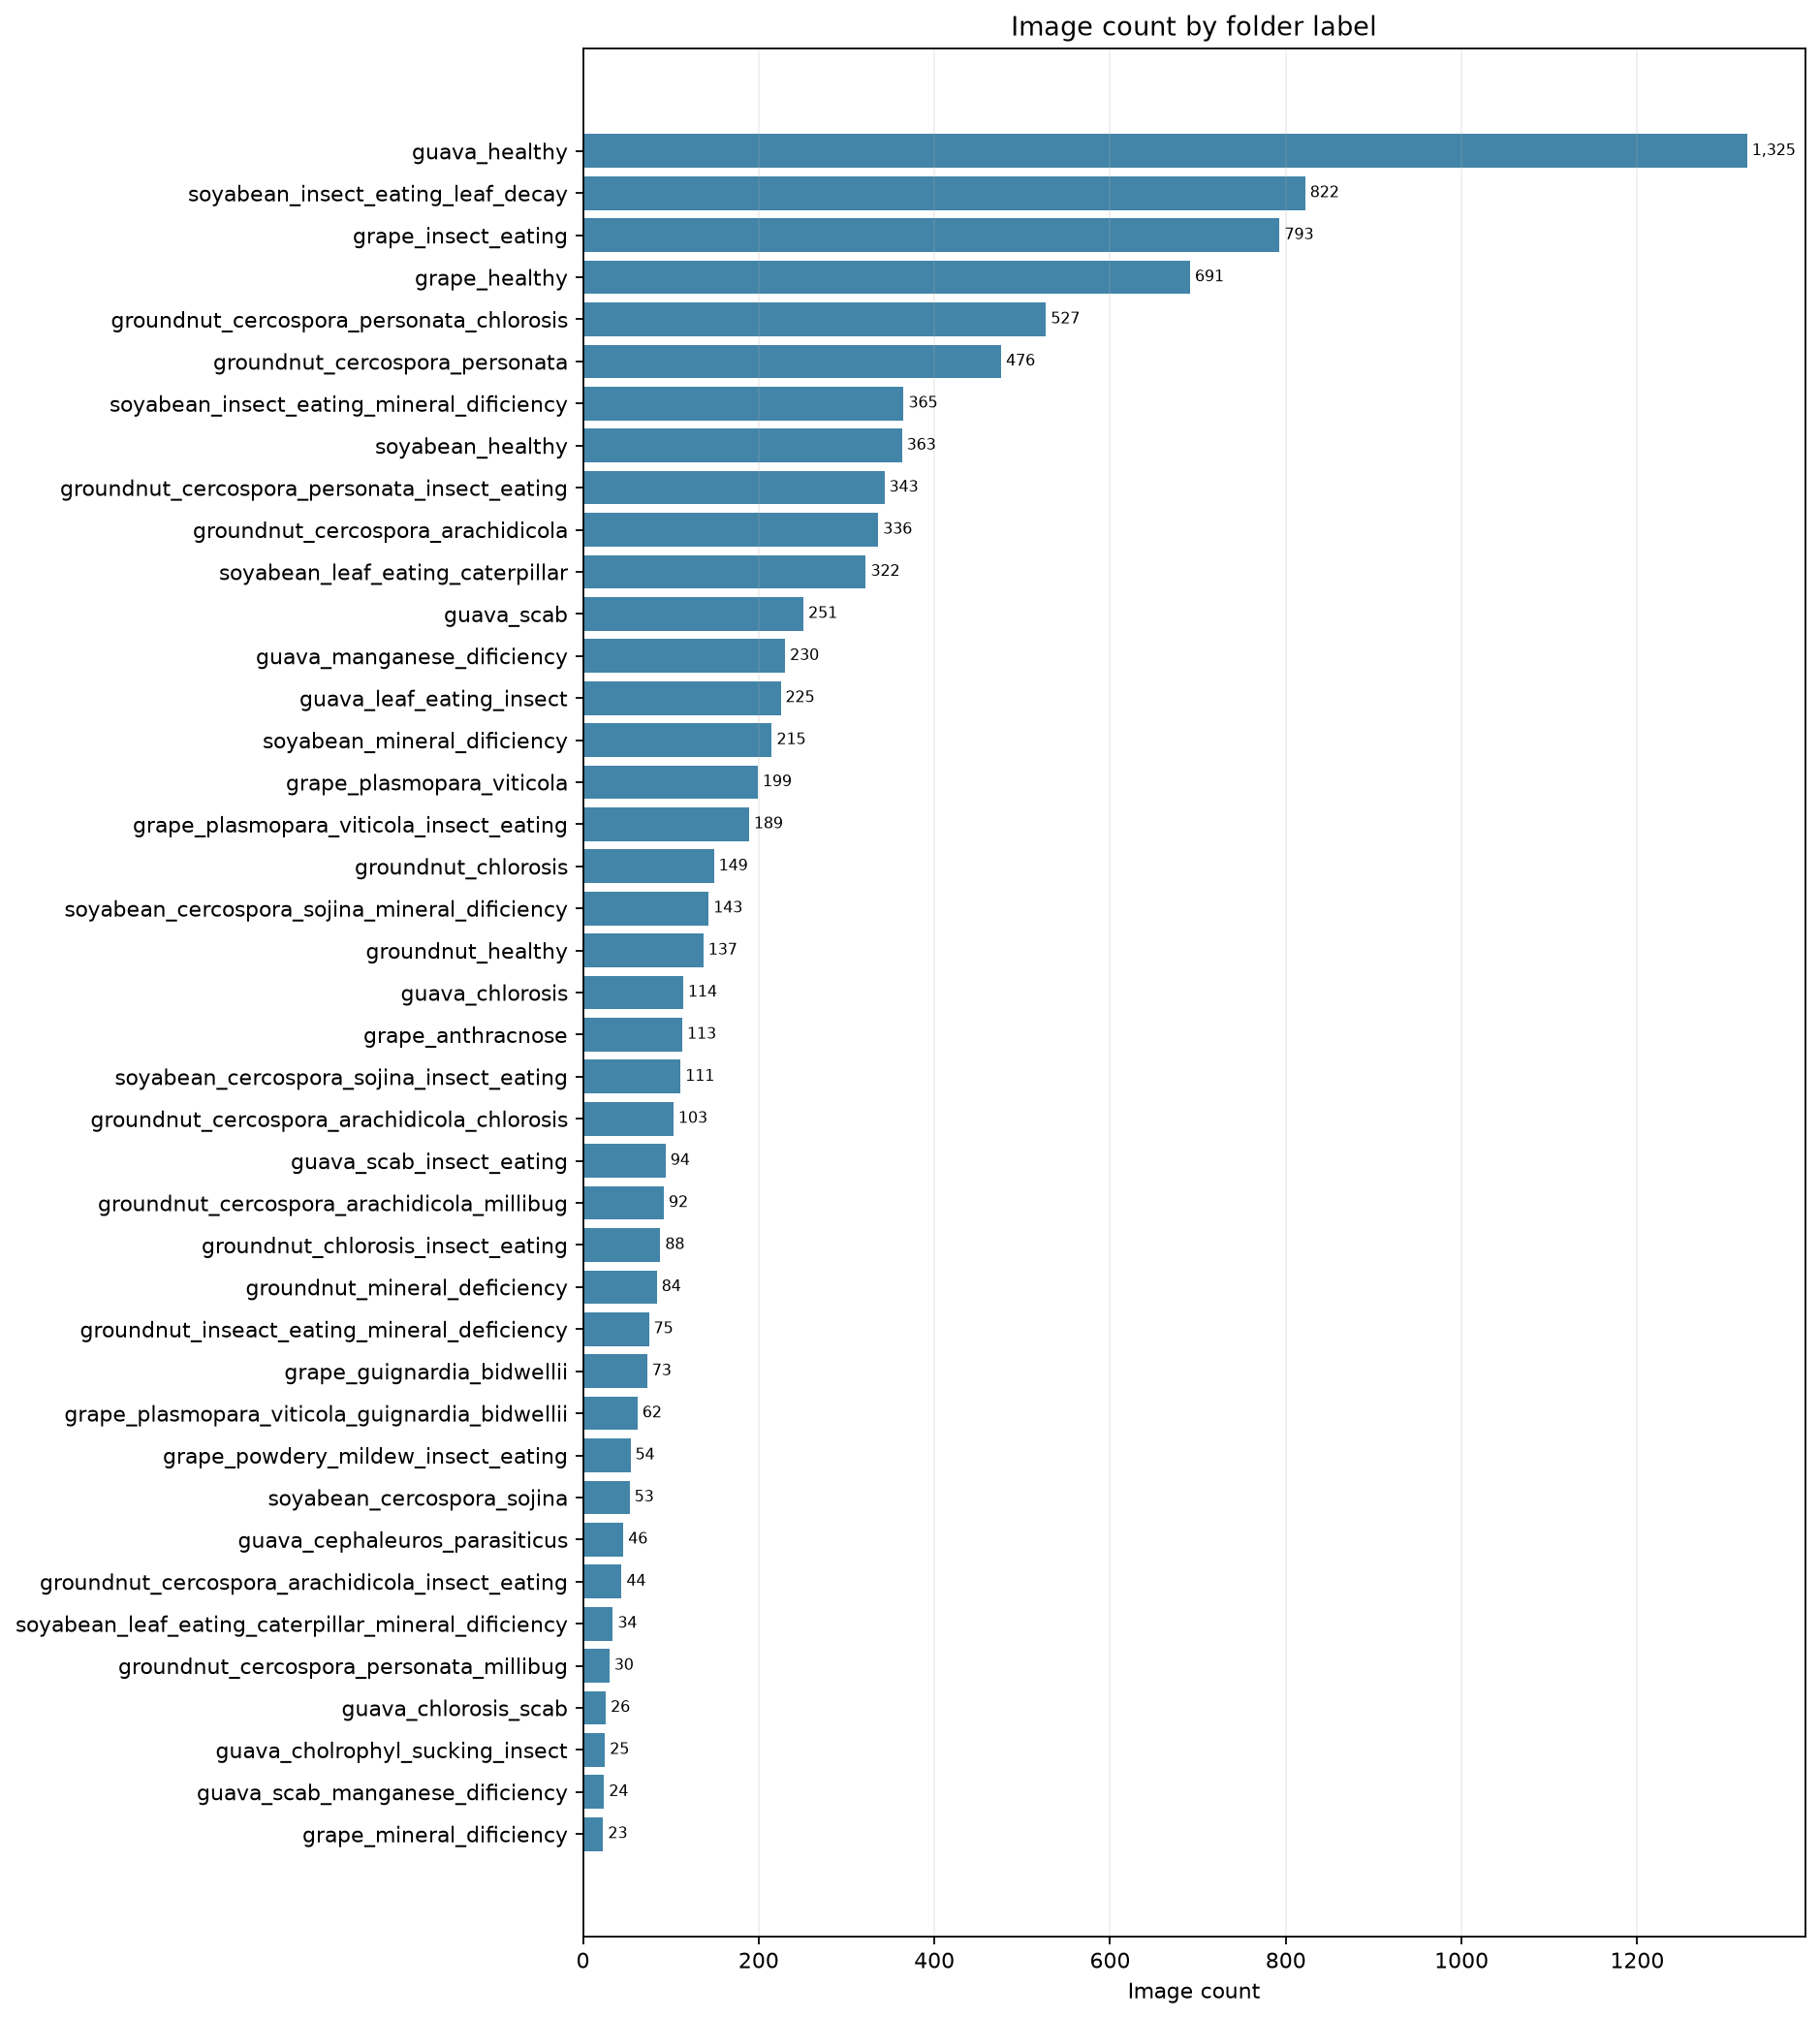

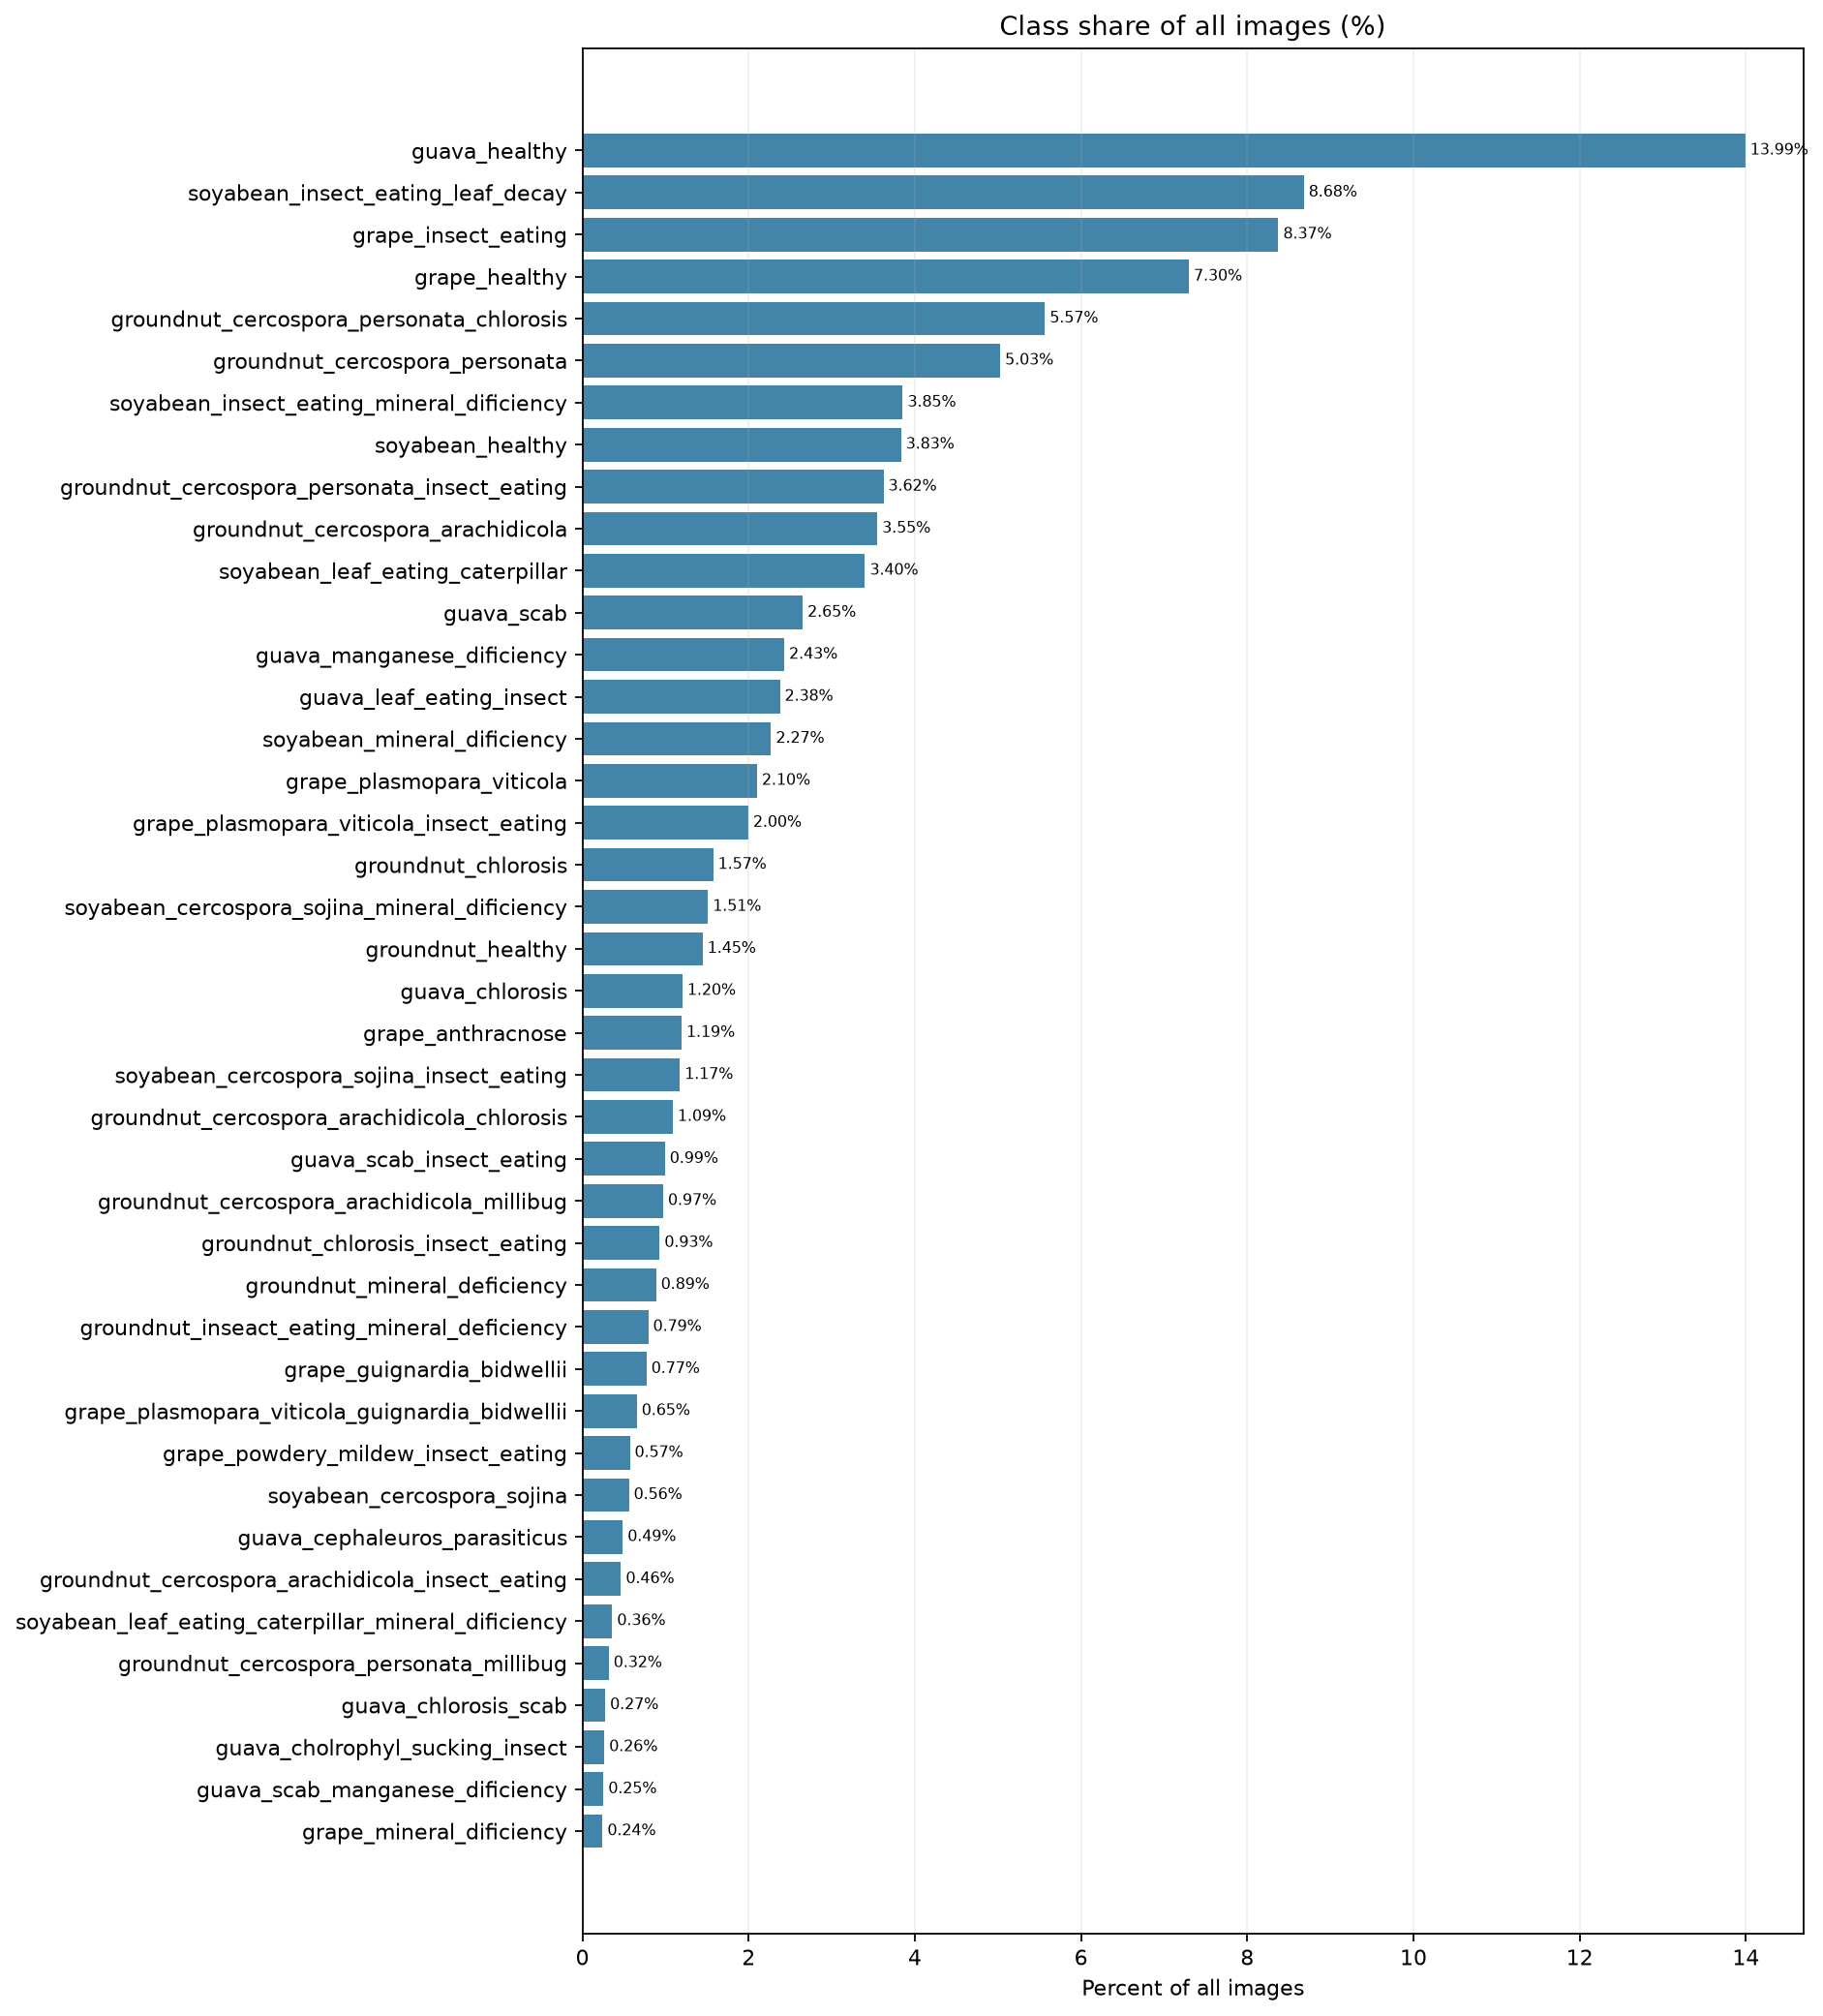

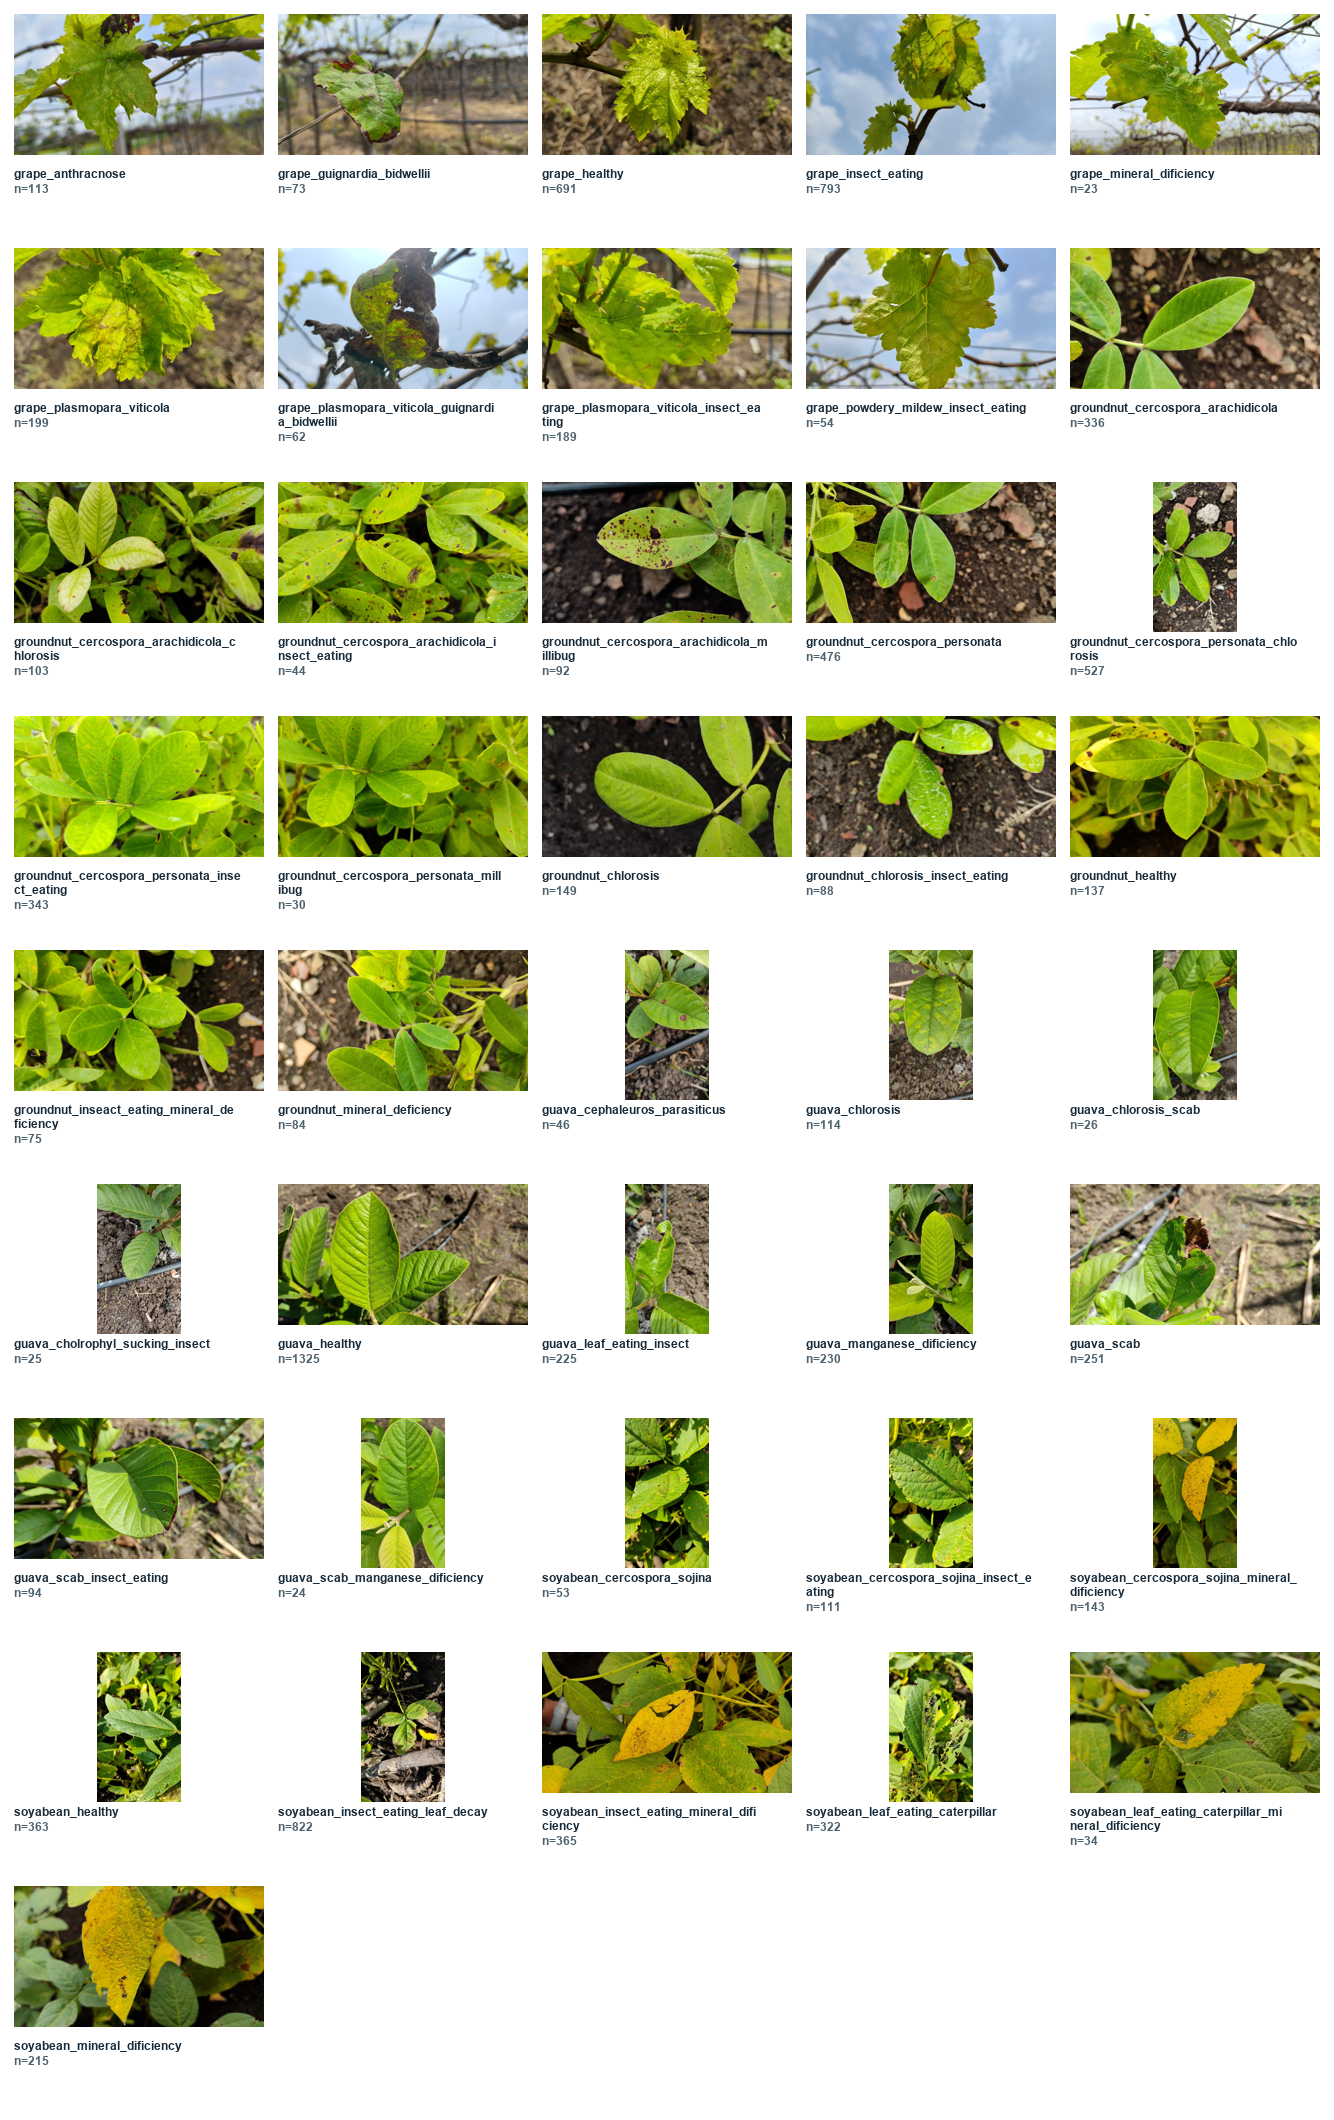

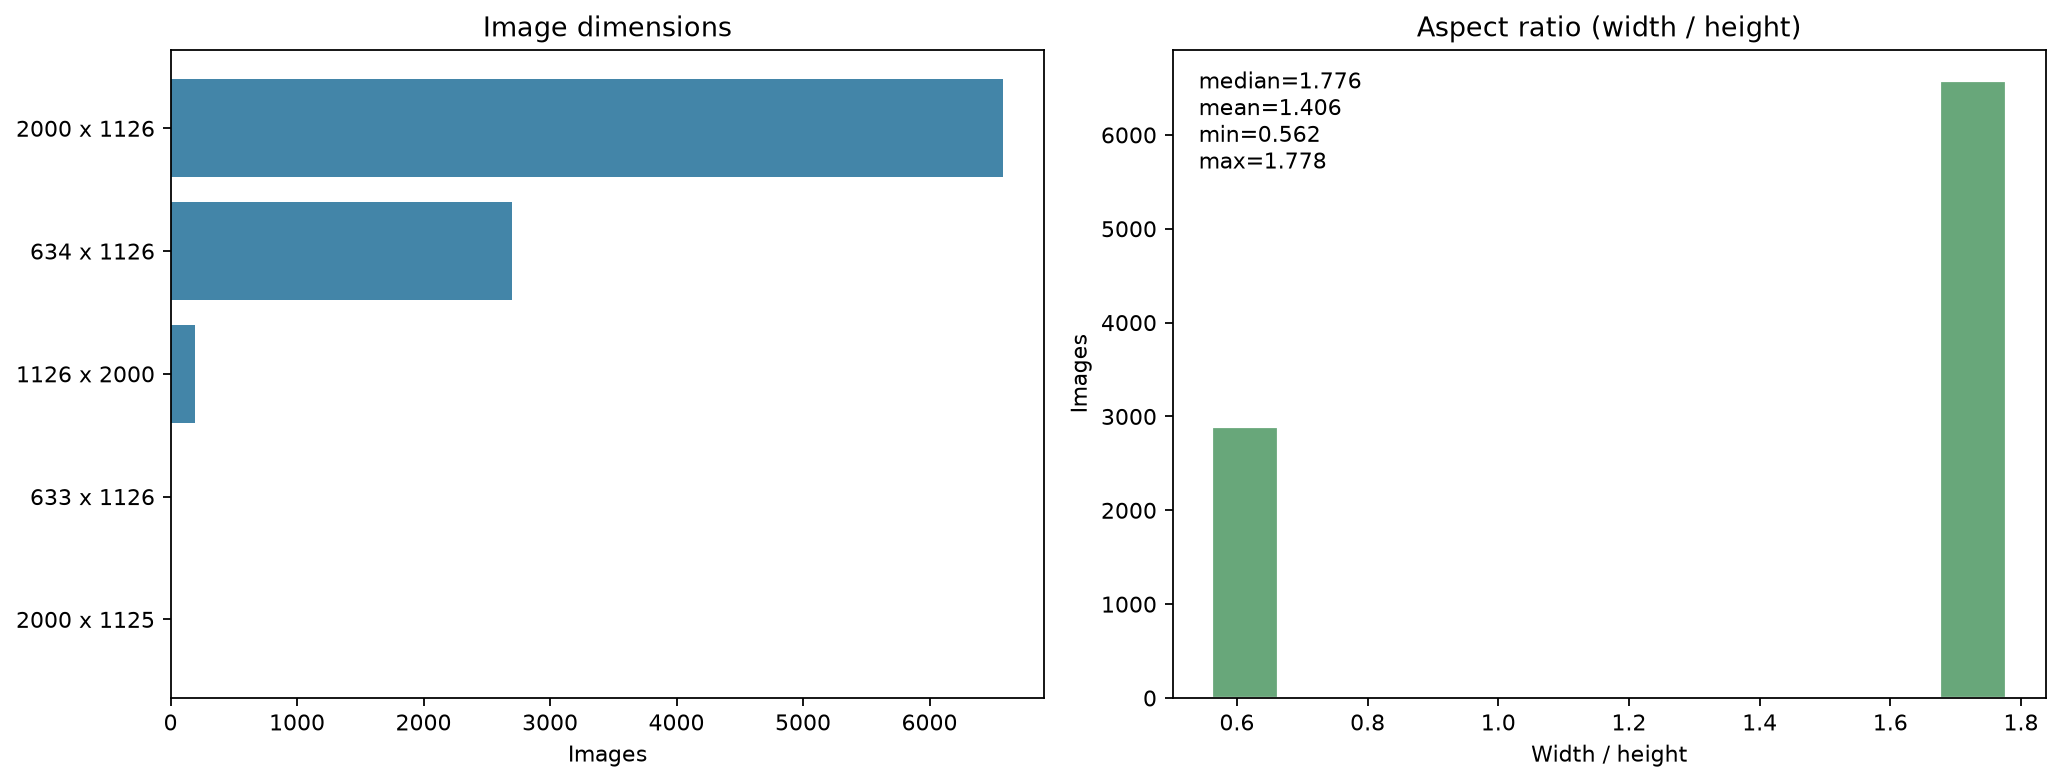

In [4]:
from IPython.display import Image, display
for name in ["class_distribution_counts.png", "class_distribution_percent.png", "sample_images_by_class.png", "image_size_aspect_ratio.png"]:
    display(Image(filename=str(ROOT / "results/figures" / name)))
